In [18]:
import os

import polars as pl

NOTEBOOK_DIR = os.path.abspath("")
BENCHMARK_DIR = os.path.join(NOTEBOOK_DIR, "benchmarks")
RESULTS_DIR = os.path.join(NOTEBOOK_DIR, "results")
PLOTS_DIR = os.path.join(RESULTS_DIR, "plots")

assert os.path.exists(NOTEBOOK_DIR), "Notebook directory does not exist"
assert os.path.exists(BENCHMARK_DIR), "Benchmark directory does not exist"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)


SAMPLE_TYPES = ['i16', 'i32', 'f32', 'f64']
SAMPLE_RATES = [44100, 48000, 96000]
CHANNELS = [1, 2]

SAMPLE_TYPE_COLOURS = {
    'i16': '#E69F00',
    'i32': '#F0E442',
    'f32': '#0072B2',
    'f64': '#009E73'
}

SAMPLE_TYPE_MARKERS = {
    'i16': 'o',
    'i32': 's',
    'f32': '^',
    'f64': 'D'
}


In [19]:
from dataclasses import dataclass
import json
from pathlib import Path
from typing import Literal, Optional
from datetime import timedelta
import altair as alt
import hvplot.polars  
import re

@dataclass
class WaversBenchCondition:
    fn_name: str
    sr: int  # Sample rate
    sample_type_name: Literal['i16', 'i32', 'f32', 'f64']
    channels: int
    duration: timedelta
    unit: Literal['s', 'ms', 'µs', 'ns'] = 'µs'
    timings_mean: float = 0.0
    pattern = re.compile(
        r'^(?P<func>\w+)<(?P<type>\w+)>: '
        r'sample_rate (?P<rate>\d+) Hz, '
        r'duration: (?P<duration>\d+) seconds, '
        r'channels: (?P<channels>\d+),\s+'
        r'avg (?P<avg>\d+)\s*(?P<unit>µs|ms|ns)'
    )
    @classmethod
    def from_str(cls, s: str):
        captures = cls.pattern.match(s)
        if not captures:
            raise ValueError(f"Invalid condition string: {s}")

        data = captures.groupdict()

        # Guarantee that the sample type is one of the expected values
        sample_type = data['type']

        if sample_type == 'i16':
            sample_type = 'i16'
        elif sample_type == 'i32':
            sample_type = 'i32'
        elif sample_type == 'f32':
            sample_type = 'f32'
        elif sample_type == 'f64':
            sample_type = 'f64'
        else:
            raise ValueError(f"Unsupported sample type: {sample_type}")

        unit = data['unit']

        # Guarantee that the duration unit is one of the expected values
        if unit == 's':
            unit = 's'
        elif unit == 'ms':
            unit = 'ms'
        elif unit == 'µs':
            unit = 'µs'
        elif unit == 'ns':
            unit = 'ns'
        else:
            raise ValueError(f"Unsupported duration unit: {unit}")

        return cls(
            fn_name=data['func'],
            sr=int(data['rate']),
            duration=timedelta(seconds=float(data['duration'])),
            sample_type_name=sample_type,
            channels=int(data['channels']),
            unit=unit,
            timings_mean=float(data['avg'])
        )


def load_bench_result(file_path: str | Path) -> list[WaversBenchCondition]:
    file_path = Path(file_path)
    with file_path.open() as f:
        lines = f.readlines()

    return [
        WaversBenchCondition.from_str(line.strip())
        for line in lines if line.strip() and not line.startswith("#")
    ]


FN_NAME_MAPPINGS = {
    "read_audio": "Read (New)", "write_audio": "Write (New)", "read": "Read (Legacy)", "write": "Write (Legacy)"
}

def map_function_name(fn_name: str) -> str:
    """
    Maps the function name to a more readable format.
    """
    return FN_NAME_MAPPINGS.get(fn_name, fn_name)


In [20]:
bench_data = load_bench_result(os.path.join(BENCHMARK_DIR, "benchmark_results.txt"))


print(f"Loaded {len(bench_data)} benchmark conditions from {BENCHMARK_DIR}")

# Create a DataFrame from the benchmark data
bench_df = pl.DataFrame({
    "fn_name": [map_function_name(cond.fn_name) for cond in bench_data],
    "sr": [cond.sr for cond in bench_data],
    "duration_secs": [cond.duration.total_seconds() for cond in bench_data],
    "sample_type": [cond.sample_type_name for cond in bench_data],
    "channels": [cond.channels for cond in bench_data],
    "unit": [cond.unit for cond in bench_data],
    "avg_time": [cond.timings_mean for cond in bench_data],
})
bench_df = bench_df.with_columns(
    pl.col("fn_name").cast(pl.Categorical),
    pl.col("sample_type").cast(pl.Categorical),
    pl.col("unit").cast(pl.Categorical)
)
bench_df = bench_df.with_columns(
    pl.col("duration_secs").cast(pl.Float64)
)
bench_df = bench_df.with_columns(
    pl.col("sr").cast(pl.Int32),
    pl.col("channels").cast(pl.Int32)
)

bench_df



Loaded 463 benchmark conditions from /home/jmg/code/rust/wavers/binaries/wavers_basic_bench/benchmarks


fn_name,sr,duration_secs,sample_type,channels,unit,avg_time
cat,i32,f64,cat,i32,cat,f64
"""Read (New)""",8000,1.0,"""i16""",1,"""µs""",3.0
"""Write (New)""",8000,1.0,"""i16""",1,"""µs""",8.0
"""Read (Legacy)""",8000,1.0,"""i16""",1,"""µs""",2.0
"""Write (New)""",8000,1.0,"""i16""",1,"""µs""",8.0
"""Read (New)""",8000,1.0,"""i32""",1,"""µs""",3.0
…,…,…,…,…,…,…
"""Read (Legacy)""",44100,60.0,"""f32""",1,"""µs""",564.0
"""Write (New)""",44100,60.0,"""f32""",1,"""µs""",2657.0
"""Read (New)""",44100,60.0,"""f64""",1,"""µs""",11344.0


# Per function performance
## Function
### X-Axis duration_secs
### Y-Axis avg_time
### Lines for each sample_type using the correct marker and colour
### New Row for each sample rate


# Old vs New function performance
## Function Class (Read or Write)
### X-Axis duration_secs
### Y-Axis avg_time
### Lines for each function (2)
### Each row will have n-sample_type figures
### New Row for each sample rate

TypeError: 'int' object is not iterable

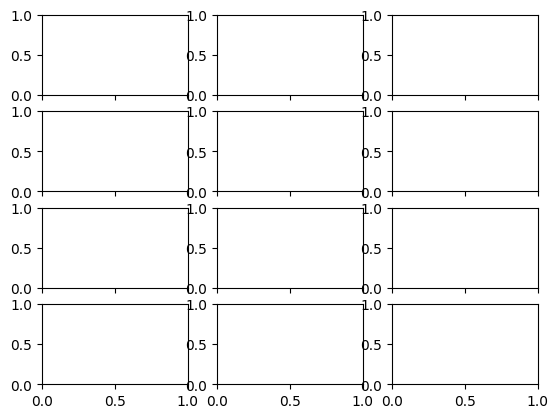

In [28]:
import matplotlib.pyplot as plt

def plot_per_function(data: pl.DataFrame):
    """
    Plots the average time per function for different sample types.
    """

    unique_sample_counts = data.select(pl.col("sample_type").n_unique()).item()

    unique_fn_names = data.select(pl.col("fn_name").unique().n_unique()).item()

    fig, axes = plt.subplots(nrows=unique_sample_counts, ncols=unique_fn_names,sharex=True)


    for i, sample_type in enumerate(unique_sample_counts):

        for j, fn_name in enumerate(unique_fn_names):
            subset = data.filter(
                (pl.col("sample_type") == sample_type) & (pl.col("fn_name") == fn_name)
            )

            if subset.is_empty():
                continue
            
            display(subset)
            # plt.subplot(len(unique_sample_counts), len(unique_fn_names), i * len(unique_fn_names) + j + 1)
            # plt.bar(subset["sr"].to_list(), subset["avg_time"].to_list(), color=SAMPLE_TYPE_COLOURS[sample_type])
            # plt.title(f"{fn_name} ({sample_type})")
            # plt.xlabel("Sample Rate (Hz)")
            # plt.ylabel("Average Time (µs)")
            # plt.xticks(subset["sr"].to_list())
            # plt.grid(True)

plot_per_function(bench_df)